In [1]:
import os
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
plt.style.use('ggplot')
from matplotlib.pyplot import figure

%matplotlib inline
matplotlib.rcParams['figure.figsize'] = (12,8)

In [2]:
df = pd.read_csv(r'C:\Users\Repair SC\Desktop\Data Analysis\movies project\movies.csv')
print(df.shape)
df.head()

(7668, 15)


,name,rating,genre,year,released,score,votes,director,writer,star,country,budget,gross,company,runtime
0,The Shining,R,Drama,1980,"June 13, 1980 (United States)",8.4,927000.0,Stanley Kubrick,Stephen King,Jack Nicholson,United Kingdom,19000000.0,46998772.0,Warner Bros.,146.0
1,The Blue Lagoon,R,Adventure,1980,"July 2, 1980 (United States)",5.8,65000.0,Randal Kleiser,Henry De Vere Stacpoole,Brooke Shields,United States,4500000.0,58853106.0,Columbia Pictures,104.0
2,Star Wars: Episode V - The Empire Strikes Back,PG,Action,1980,"June 20, 1980 (United States)",8.7,1200000.0,Irvin Kershner,Leigh Brackett,Mark Hamill,United States,18000000.0,538375067.0,Lucasfilm,124.0
3,Airplane!,PG,Comedy,1980,"July 2, 1980 (United States)",7.7,221000.0,Jim Abrahams,Jim Abrahams,Robert Hays,United States,3500000.0,83453539.0,Paramount Pictures,88.0
4,Caddyshack,R,Comedy,1980,"July 25, 1980 (United States)",7.3,108000.0,Harold Ramis,Brian Doyle-Murray,Chevy Chase,United States,6000000.0,39846344.0,Orion Pictures,98.0


In [3]:
#Loss percentage
(df.isna().sum() / len(df)) * 100

#not gonna remove nulls bc corr() function will ignore them anyway.

name         0.000000
rating       1.004173
genre        0.000000
year         0.000000
released     0.026082
score        0.039124
votes        0.039124
director     0.000000
writer       0.039124
star         0.013041
country      0.039124
budget      28.312467
gross        2.464789
company      0.221701
runtime      0.052165
dtype: float64

In [4]:
df.dtypes

name            str
rating          str
genre           str
year          int64
released        str
score       float64
votes       float64
director        str
writer          str
star            str
country         str
budget      float64
gross       float64
company         str
runtime     float64
dtype: object

In [ ]:
#CHANGE DAATA TYPE OF COLUMNS
df['budget'] = df['budget'].astype('Int64')
df['votes'] = df['votes'].astype('Int64')
df['gross'] = df['gross'].astype('Int64')
#Int accepts null values, while int does not. So we use Int64 instead of int.
df

,name,rating,genre,year,released,score,votes,director,writer,star,country,budget,gross,company,runtime
0,The Shining,R,Drama,1980,"June 13, 1980 (United States)",8.4,927000,Stanley Kubrick,Stephen King,Jack Nicholson,United Kingdom,19000000,46998772,Warner Bros.,146.0
1,The Blue Lagoon,R,Adventure,1980,"July 2, 1980 (United States)",5.8,65000,Randal Kleiser,Henry De Vere Stacpoole,Brooke Shields,United States,4500000,58853106,Columbia Pictures,104.0
2,Star Wars: Episode V - The Empire Strikes Back,PG,Action,1980,"June 20, 1980 (United States)",8.7,1200000,Irvin Kershner,Leigh Brackett,Mark Hamill,United States,18000000,538375067,Lucasfilm,124.0
3,Airplane!,PG,Comedy,1980,"July 2, 1980 (United States)",7.7,221000,Jim Abrahams,Jim Abrahams,Robert Hays,United States,3500000,83453539,Paramount Pictures,88.0
4,Caddyshack,R,Comedy,1980,"July 25, 1980 (United States)",7.3,108000,Harold Ramis,Brian Doyle-Murray,Chevy Chase,United States,6000000,39846344,Orion Pictures,98.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7663,More to Life,NaN,Drama,2020,"October 23, 2020 (United States)",3.1,18,Joseph Ebanks,Joseph Ebanks,Shannon Bond,United States,7000,<NA>,NaN,90.0
7664,Dream Round,NaN,Comedy,2020,"February 7, 2020 (United States)",4.7,36,Dusty Dukatz,Lisa Huston,Michael Saquella,United States,<NA>,<NA>,Cactus Blue Entertainment,90.0
7665,Saving Mbango,NaN,Drama,2020,"April 27, 2020 (Cameroon)",5.7,29,Nkanya Nkwai,Lynno Lovert,Onyama Laura,United States,58750,<NA>,Embi Productions,NaN
7666,It's Just Us,NaN,Drama,2020,"October 1, 2020 (United States)",NaN,<NA>,James Randall,James Randall,Christina Roz,United States,15000,<NA>,NaN,120.0


In [ ]:
df['year_released'] = df['released'].str.extract(r'(\d{4})')


In [ ]:
#show columns that doesn't match
df['year_released'] = df['year_released'].astype('Int64')
print((df[df['year_released'] != df['year']][['year_released', 'year']].count()))
print(df[df['year_released'] != df['year']][['year_released', 'year']])

year_released    1324
year             1324
dtype: int64
      year_released  year
8              1981  1980
11             1984  1980
21             1981  1980
33             1981  1980
40             1981  1980
...             ...   ...
7525           2020  2019
7580           2020  2019
7584           2020  2019
7604           2020  2019
7641           2020  2019

[1324 rows x 2 columns]


In [33]:
df.sort_values(by=['gross'], inplace=False, ascending=False)

,name,rating,genre,year,released,score,votes,director,writer,star,country,budget,gross,company,runtime,year_released
5445,Avatar,PG-13,Action,2009,"December 18, 2009 (United States)",7.8,1100000,James Cameron,James Cameron,Sam Worthington,United States,237000000,2847246203,Twentieth Century Fox,162.0,2009
7445,Avengers: Endgame,PG-13,Action,2019,"April 26, 2019 (United States)",8.4,903000,Anthony Russo,Christopher Markus,Robert Downey Jr.,United States,356000000,2797501328,Marvel Studios,181.0,2019
3045,Titanic,PG-13,Drama,1997,"December 19, 1997 (United States)",7.8,1100000,James Cameron,James Cameron,Leonardo DiCaprio,United States,200000000,2201647264,Twentieth Century Fox,194.0,1997
6663,Star Wars: Episode VII - The Force Awakens,PG-13,Action,2015,"December 18, 2015 (United States)",7.8,876000,J.J. Abrams,Lawrence Kasdan,Daisy Ridley,United States,245000000,2069521700,Lucasfilm,138.0,2015
7244,Avengers: Infinity War,PG-13,Action,2018,"April 27, 2018 (United States)",8.4,897000,Anthony Russo,Christopher Markus,Robert Downey Jr.,United States,321000000,2048359754,Marvel Studios,149.0,2018
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7663,More to Life,NaN,Drama,2020,"October 23, 2020 (United States)",3.1,18,Joseph Ebanks,Joseph Ebanks,Shannon Bond,United States,7000,<NA>,NaN,90.0,2020
7664,Dream Round,NaN,Comedy,2020,"February 7, 2020 (United States)",4.7,36,Dusty Dukatz,Lisa Huston,Michael Saquella,United States,<NA>,<NA>,Cactus Blue Entertainment,90.0,2020
7665,Saving Mbango,NaN,Drama,2020,"April 27, 2020 (Cameroon)",5.7,29,Nkanya Nkwai,Lynno Lovert,Onyama Laura,United States,58750,<NA>,Embi Productions,NaN,2020
7666,It's Just Us,NaN,Drama,2020,"October 1, 2020 (United States)",NaN,<NA>,James Randall,James Randall,Christina Roz,United States,15000,<NA>,NaN,120.0,2020


In [37]:
#to show all rows in the dataframe, uncomment the following line
# pd.set_option('display.max_rows', None)
# df

In [48]:
#check for duplicates
df['company'].drop_duplicates().sort_values(ascending=False)

7129                                              thefyzz
5664                                          micro_scope
6412                             iDeal Partners Film Fund
4007                                             i5 Films
6793                                           i am OTHER
6420                                                 erbp
3776                                       double A Films
524                             Zupnik-Curtis Enterprises
3330                          Zucker Brothers Productions
146                                      Zoetrope Studios
2213                                   Zeta Entertainment
6222                        Zentropa International Norway
3368                              Zentropa Entertainments
535                                  Zenith Entertainment
5180                                      Zazen Produções
3193                                          ZapPictures
1321                             Zanuck/Brown Productions
1329          

In [58]:
 # check correlations
cols = ["gross", "budget", "score"]

# ارتباط بيرسون على الأعمدة الثلاثة فقط
corr_pearson = df[cols].corr(method="pearson")
print(corr_pearson)

# ارتباط سبيرمان أيضاً للمقارنة
corr_spearman = df[cols].corr(method="spearman")
print(corr_spearman)


           gross    budget     score
gross   1.000000  0.740395  0.186258
budget  0.740395  1.000000  0.076254
score   0.186258  0.076254  1.000000
           gross    budget     score
gross   1.000000  0.693670  0.126116
budget  0.693670  1.000000 -0.001403
score   0.126116 -0.001403  1.000000


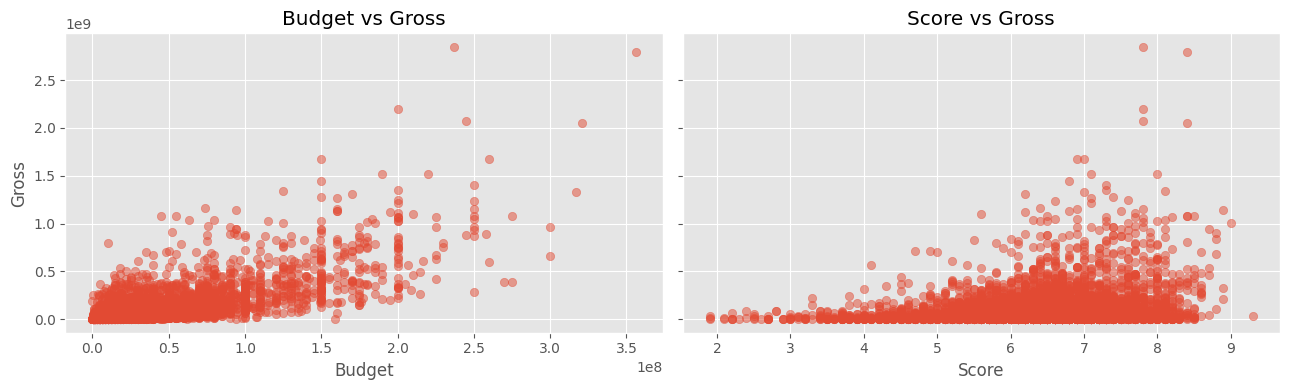

In [59]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)

axes[0].scatter(df["budget"], df["gross"], alpha=0.5)
axes[0].set_title("Budget vs Gross")
axes[0].set_xlabel("Budget")
axes[0].set_ylabel("Gross")

axes[1].scatter(df["score"], df["gross"], alpha=0.5)
axes[1].set_title("Score vs Gross")
axes[1].set_xlabel("Score")

plt.tight_layout()
plt.show()

<Axes: xlabel='budget', ylabel='gross'>

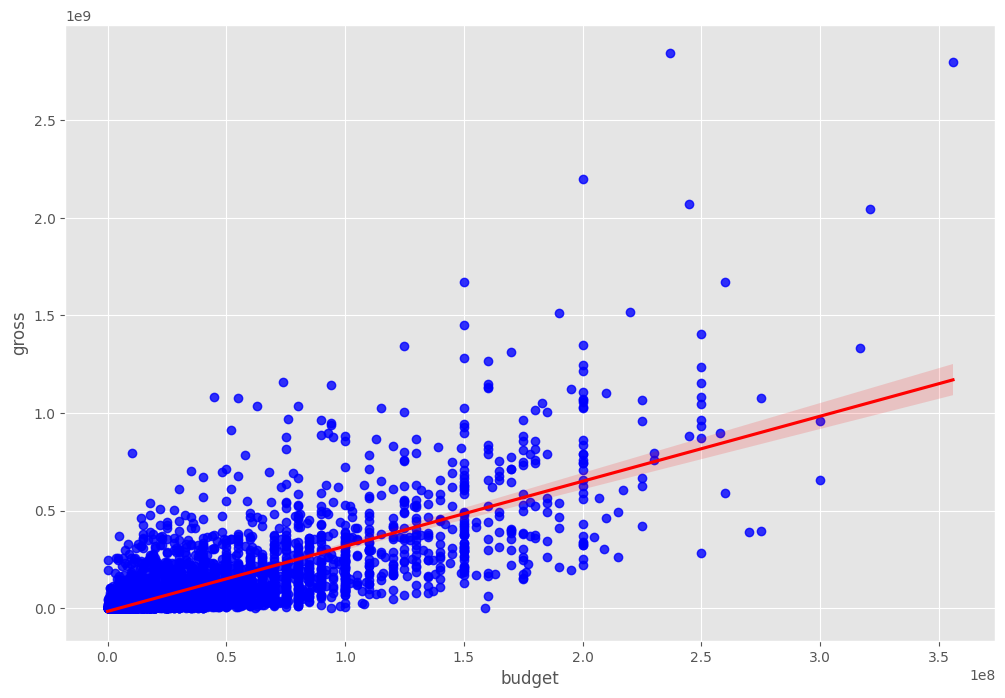

In [60]:
#plot budget vs gross using seaborn
sns.regplot(x="budget", y="gross", data=df, scatter_kws={"color": "blue"}, line_kws={"color": "red"})

In [64]:
correlations= df.corr(numeric_only=True)

Text(0.5, 1.0, 'Correlation Heatmap')

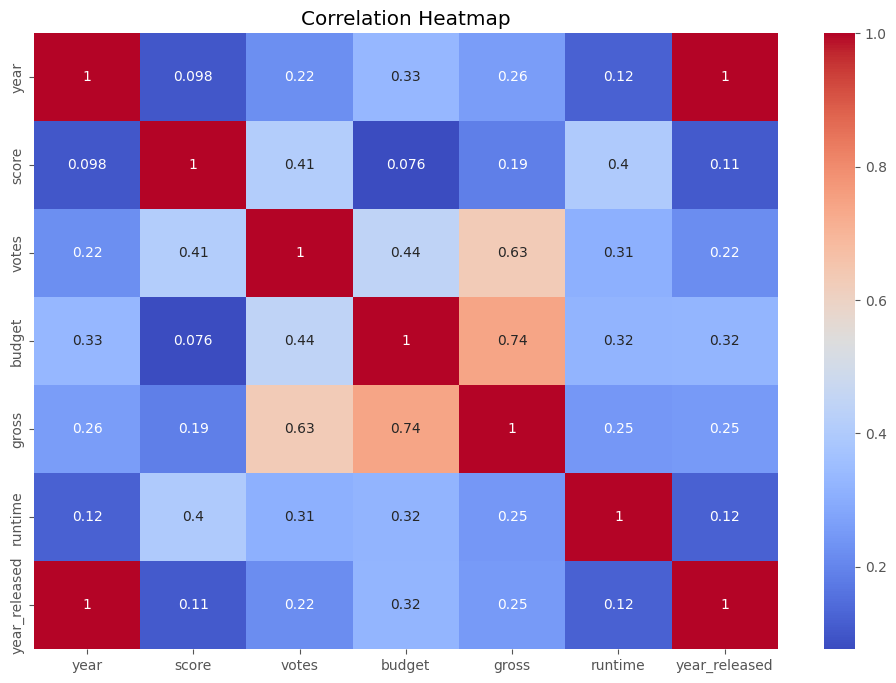

In [67]:
sns.heatmap(correlations, annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")


In [71]:
 # check correlation with non-numeric columns
df_numerized = df.copy()
for col in df_numerized.columns:
    if df_numerized[col].dtype == 'str':
        df_numerized[col] = df_numerized[col].astype('category')
        df_numerized[col] = df_numerized[col].cat.codes

df_numerized.head()

,name,rating,genre,year,released,score,votes,director,writer,star,country,budget,gross,company,runtime,year_released
0,6587,6,6,1980,1705,8.4,927000,2589,4014,1047,54,19000000,46998772,2319,146.0,1980
1,5573,6,1,1980,1492,5.8,65000,2269,1632,327,55,4500000,58853106,731,104.0,1980
2,5142,4,0,1980,1771,8.7,1200000,1111,2567,1745,55,18000000,538375067,1540,124.0,1980
3,286,4,4,1980,1492,7.7,221000,1301,2000,2246,55,3500000,83453539,1812,88.0,1980
4,1027,6,4,1980,1543,7.3,108000,1054,521,410,55,6000000,39846344,1777,98.0,1980


In [73]:
df_numerized.corr()

,name,rating,genre,year,released,score,votes,director,writer,star,country,budget,gross,company,runtime,year_released
name,1.000000,-0.008069,0.016355,0.011453,-0.011311,0.017097,0.013088,0.009079,0.009081,0.006472,-0.010737,0.023970,0.005533,0.009211,0.010392,0.010699
rating,-0.008069,1.000000,0.072423,0.008779,0.016613,-0.001314,0.033225,0.019483,-0.005921,0.013405,0.081244,-0.176002,-0.107339,-0.032943,0.062145,0.006741
genre,0.016355,0.072423,1.000000,-0.081261,0.029822,0.027965,-0.145307,-0.015258,0.006567,-0.005477,-0.037615,-0.356564,-0.235650,-0.071067,-0.052711,-0.077911
year,0.011453,0.008779,-0.081261,1.000000,-0.000695,0.097995,0.222945,-0.020795,-0.008656,-0.027242,-0.070938,0.329321,0.257486,-0.010431,0.120811,0.997415
released,-0.011311,0.016613,0.029822,-0.000695,1.000000,0.042788,0.016097,-0.001478,-0.002404,0.015777,-0.020427,0.014683,0.001659,-0.010474,0.000868,-0.004644
score,0.017097,-0.001314,0.027965,0.097995,0.042788,1.000000,0.409182,0.009559,0.019416,-0.001609,-0.133348,0.076254,0.186258,0.001030,0.399451,0.105994
votes,0.013088,0.033225,-0.145307,0.222945,0.016097,0.409182,1.000000,0.000260,0.000892,-0.019282,0.073625,0.442429,0.630757,0.133204,0.309212,0.218429
director,0.009079,0.019483,-0.015258,-0.020795,-0.001478,0.009559,0.000260,1.000000,0.299067,0.039234,0.017490,-0.012272,-0.014441,0.004404,0.017624,-0.020422
writer,0.009081,-0.005921,0.006567,-0.008656,-0.002404,0.019416,0.000892,0.299067,1.000000,0.027245,0.015343,-0.039451,-0.023519,0.005646,-0.003511,-0.008611
star,0.006472,0.013405,-0.005477,-0.027242,0.015777,-0.001609,-0.019282,0.039234,0.027245,1.000000,-0.012998,-0.019589,-0.002717,0.012442,0.010174,-0.027611


Text(0.5, 1.0, 'Correlation Heatmap')

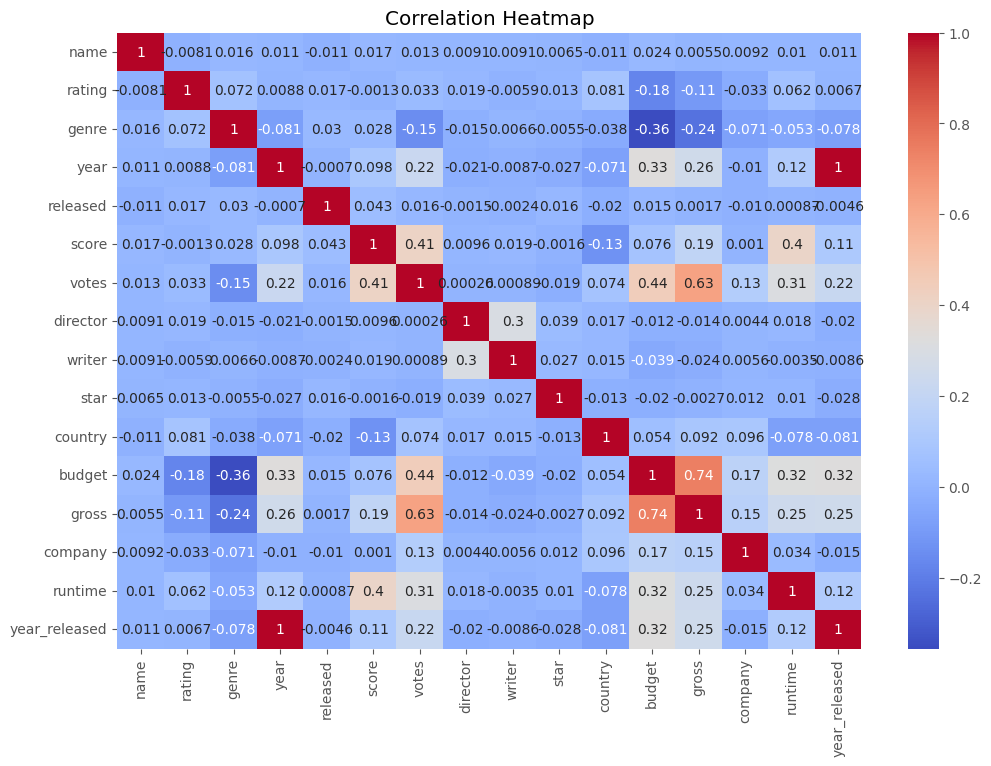

In [74]:
correlation_total = df_numerized.corr(method='pearson')

sns.heatmap(correlation_total, annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")


In [76]:
correlation_matrix= df_numerized.corr()
corr_pairs = correlation_matrix.unstack()
corr_pairs

name           name             1.000000
               rating          -0.008069
               genre            0.016355
               year             0.011453
               released        -0.011311
               score            0.017097
               votes            0.013088
               director         0.009079
               writer           0.009081
               star             0.006472
               country         -0.010737
               budget           0.023970
               gross            0.005533
               company          0.009211
               runtime          0.010392
               year_released    0.010699
rating         name            -0.008069
               rating           1.000000
               genre            0.072423
               year             0.008779
               released         0.016613
               score           -0.001314
               votes            0.033225
               director         0.019483
               w

In [79]:
corr_pairs_sorted = corr_pairs.sort_values().sort_values(ascending=False)
corr_pairs_sorted

director       director         1.000000
votes          votes            1.000000
released       released         1.000000
score          score            1.000000
rating         rating           1.000000
name           name             1.000000
genre          genre            1.000000
year           year             1.000000
budget         budget           1.000000
country        country          1.000000
writer         writer           1.000000
star           star             1.000000
company        company          1.000000
gross          gross            1.000000
runtime        runtime          1.000000
year_released  year_released    1.000000
               year             0.997415
year           year_released    0.997415
budget         gross            0.740395
gross          budget           0.740395
votes          gross            0.630757
gross          votes            0.630757
budget         votes            0.442429
votes          budget           0.442429
               s

In [82]:
#call high correlation pairs
high_corr = corr_pairs_sorted[corr_pairs_sorted > 0.5]
high_corr

director       director         1.000000
votes          votes            1.000000
released       released         1.000000
score          score            1.000000
rating         rating           1.000000
name           name             1.000000
genre          genre            1.000000
year           year             1.000000
budget         budget           1.000000
country        country          1.000000
writer         writer           1.000000
star           star             1.000000
company        company          1.000000
gross          gross            1.000000
runtime        runtime          1.000000
year_released  year_released    1.000000
               year             0.997415
year           year_released    0.997415
budget         gross            0.740395
gross          budget           0.740395
votes          gross            0.630757
gross          votes            0.630757
dtype: float64

In [ ]:
# conclusion: budget and votes have the highest correlation with gross earnings. This suggests that movies with higher budgets and more votes tend to earn more at the box office.